# 02 · Etapa 0 y Nivel 1: portero vs. campo, y Fisher + KNN

Decisiones tomadas tras la exploración (`01_exploracion.ipynb`):

- Los porteros son casi trivialmente separables, así que se resuelven con una **compuerta previa** (Etapa 0).
- El **Nivel 1** clasifica solo jugadores de campo en 3 clases (Defensa, Medio, Delantero) con **Fisher + KNN**. Con 3 clases, Fisher produce exactamente 2 discriminantes.
- Todo lo que se ajusta (escalado, Fisher, KNN) usa **solo datos de entrenamiento**.

```
Jugador → Etapa 0: ¿portero o campo?
            ├─ Portero → fin
            └─ Campo → Nivel 1 (Fisher + KNN): Defensa / Medio / Delantero
```

Fisher y KNN son implementaciones propias en `src/models/` (NumPy), validadas aquí contra scikit-learn.

In [1]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

from src.models.fisher import FisherLDA
from src.models.knn import KNNClassifier

sns.set_theme(style="whitegrid")

SEED = 42
DATA = Path("..") / "data" / "processed" / "jugadores_procesados.csv"
ORDEN_4 = ["Portero", "Defensa", "Medio", "Delantero"]
ORDEN_CAMPO = ["Defensa", "Medio", "Delantero"]
ID_COLS = ["player_id", "short_name", "posicion_principal", "y_gen"]

df = pd.read_csv(DATA)
metricas = [c for c in df.columns if c not in ID_COLS]
portero_cols = [c for c in metricas if c.startswith("goalkeeping_")]
metricas_campo = [c for c in metricas if c not in portero_cols]
print(f"{len(df):,} jugadores · {len(metricas)} métricas ({len(portero_cols)} de portero, {len(metricas_campo)} de campo)")

18,350 jugadores · 43 métricas (6 de portero, 37 de campo)


## 1. Partición entrenamiento / prueba

Se estratifica por **posición específica** (`posicion_principal`), no solo por `y_gen`. Así se conservan las proporciones de las 4 clases y también las de cada posición, que necesitaremos intactas en el Nivel 2. El conjunto de prueba no se toca hasta la evaluación final.

In [2]:
train, test = train_test_split(df, test_size=0.2, stratify=df["posicion_principal"], random_state=SEED)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

prop = pd.DataFrame({
    "train (%)": train["y_gen"].value_counts(normalize=True).reindex(ORDEN_4) * 100,
    "test (%)": test["y_gen"].value_counts(normalize=True).reindex(ORDEN_4) * 100,
}).round(1)
print(f"train: {len(train):,} · test: {len(test):,}")
display(prop)

train: 14,680 · test: 3,670


,train (%),test (%)
y_gen,,
Portero,11.1,11.1
Defensa,33.6,33.7
Medio,36.4,36.4
Delantero,18.8,18.8


## 2. Etapa 0: compuerta portero vs. campo

Un árbol de decisión de profundidad 1 (un solo umbral), entrenado **solo con las columnas `goalkeeping_*`**. Se evita usar las métricas de campo porque en los porteros están rellenas con 0, y una regla basada en ese relleno no funcionaría con jugadores nuevos.

In [3]:
gate = DecisionTreeClassifier(max_depth=1, random_state=SEED)
gate.fit(train[portero_cols], train["y_gen"] == "Portero")

print(export_text(gate, feature_names=portero_cols))

es_portero_real = (test["y_gen"] == "Portero").to_numpy()
es_portero_pred = gate.predict(test[portero_cols]).astype(bool)

print(f"Exactitud de la compuerta en prueba: {accuracy_score(es_portero_real, es_portero_pred):.4f}")
display(pd.crosstab(
    pd.Series(es_portero_real, name="real es portero"),
    pd.Series(es_portero_pred, name="predicho portero"),
))

fallos = test.loc[es_portero_real != es_portero_pred, ["short_name", "posicion_principal"]]
print(f"Errores de la compuerta: {len(fallos)}")
if len(fallos):
    display(fallos)

|--- goalkeeping_reflexes <= 39.50
|   |--- class: False
|--- goalkeeping_reflexes >  39.50
|   |--- class: True

Exactitud de la compuerta en prueba: 1.0000


predicho portero,False,True
real es portero,,
False,3261,0
True,0,409


Errores de la compuerta: 0


**Lectura:** si la exactitud es ~100%, la Etapa 0 queda resuelta y los errores del pipeline vendrán casi por completo del Nivel 1. Si hay errores, conviene revisar esos jugadores (por ejemplo, un jugador de campo con una posición ambigua en el dataset).

## 3. Rama de campo: preparación

El Nivel 1 se entrena **con las etiquetas reales** de los jugadores de campo del entrenamiento (no con las predicciones de la compuerta) y sin las columnas `goalkeeping_*`.

In [4]:
train_campo = train[train["y_gen"] != "Portero"]
test_campo = test[test["y_gen"] != "Portero"]

X_tr = train_campo[metricas_campo].to_numpy(dtype=float)
y_tr = train_campo["y_gen"].to_numpy()
X_te = test_campo[metricas_campo].to_numpy(dtype=float)
y_te = test_campo["y_gen"].to_numpy()

print(f"Campo → train: {len(X_tr):,} · test: {len(X_te):,} · métricas: {X_tr.shape[1]}")

# Redundancia ahora que los porteros ya no inflan las correlaciones
corr = train_campo[metricas_campo].corr()
tri = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
n_pares = int((tri.abs().stack() > 0.90).sum())
print(f"Pares con |r| > 0.90 solo en jugadores de campo: {n_pares} (con porteros eran 47)")

Campo → train: 13,044 · test: 3,261 · métricas: 37
Pares con |r| > 0.90 solo en jugadores de campo: 17 (con porteros eran 47)


## 4. Fisher sobre jugadores de campo

In [5]:
scaler = StandardScaler().fit(X_tr)
Xs_tr = scaler.transform(X_tr)

fisher = FisherLDA().fit(Xs_tr, y_tr)
Z_tr = fisher.transform(Xs_tr)

print("Clases:", list(fisher.classes_))
print("Razón de separación por discriminante:", fisher.explained_ratio_.round(3))

# Validación: el subespacio debe coincidir con el de scikit-learn
def r2_subespacio(Z_a, Z_b):
    A = np.c_[Z_b, np.ones(len(Z_b))]
    coef = np.linalg.lstsq(A, Z_a, rcond=None)[0]
    return 1 - ((Z_a - A @ coef) ** 2).sum() / ((Z_a - Z_a.mean(0)) ** 2).sum()

sk = LinearDiscriminantAnalysis(solver="svd").fit(Xs_tr, y_tr)
print(f"R² entre mi proyección y la de scikit-learn: {r2_subespacio(Z_tr, sk.transform(Xs_tr)[:, :2]):.4f}  (≈ 1 = mismo subespacio)")

Clases: ['Defensa', 'Delantero', 'Medio']
Razón de separación por discriminante: [0.794 0.206]
R² entre mi proyección y la de scikit-learn: 1.0000  (≈ 1 = mismo subespacio)


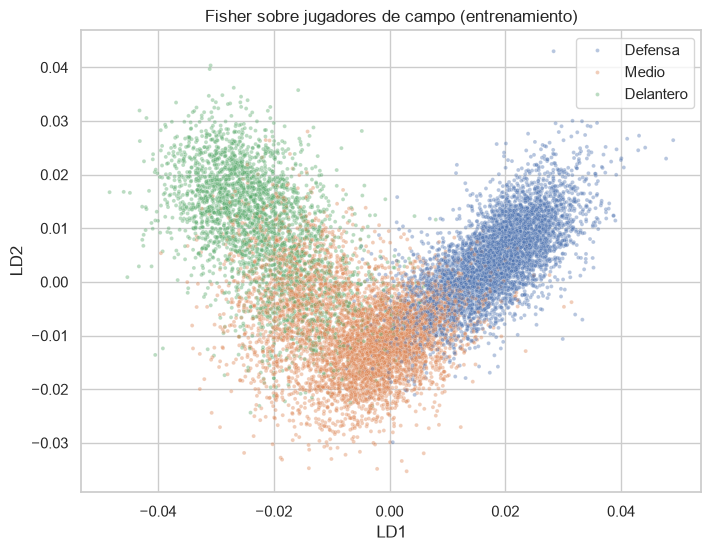


Métricas con mayor peso absoluto en LD1:


,LD1
physic,-0.450
attacking_finishing,-0.393
attacking_crossing,0.348
defending_sliding_tackle,0.343
power_strength,0.247
mentality_vision,-0.229
defending_marking_awareness,0.205
shooting,0.197



Métricas con mayor peso absoluto en LD2:


,LD2
skill_long_passing,-0.322
mentality_vision,-0.322
defending,0.295
shooting,-0.293
dribbling,0.282
defending_standing_tackle,-0.269
attacking_heading_accuracy,0.266
skill_dribbling,-0.212


In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=Z_tr[:, 0], y=Z_tr[:, 1], hue=y_tr, hue_order=ORDEN_CAMPO, s=8, alpha=0.4, ax=ax)
ax.set_title("Fisher sobre jugadores de campo (entrenamiento)")
ax.set_xlabel("LD1")
ax.set_ylabel("LD2")
plt.show()

pesos = pd.DataFrame(fisher.components_, index=metricas_campo, columns=["LD1", "LD2"])
pesos = pesos / np.linalg.norm(pesos, axis=0)  # cada discriminante con norma 1
for ld in ["LD1", "LD2"]:
    print(f"\nMétricas con mayor peso absoluto en {ld}:")
    display(pesos[ld].reindex(pesos[ld].abs().sort_values(ascending=False).index).head(8).round(3).to_frame())

**Lectura:** los pesos (normalizados a norma 1) se aplican a métricas estandarizadas, así que son comparables entre sí. Con métricas muy correlacionadas, el peso se reparte entre ellas y puede haber signos que se compensan; interprétalos con cautela y compáralos con el perfil medio de `01_exploracion`.

## 5. Elección de k con validación cruzada

El escalado y Fisher se **reajustan dentro de cada pliegue**, de modo que el pliegue de validación nunca influye en la proyección. Se calculan los vecinos una sola vez con el k máximo y se recortan columnas para probar cada k.

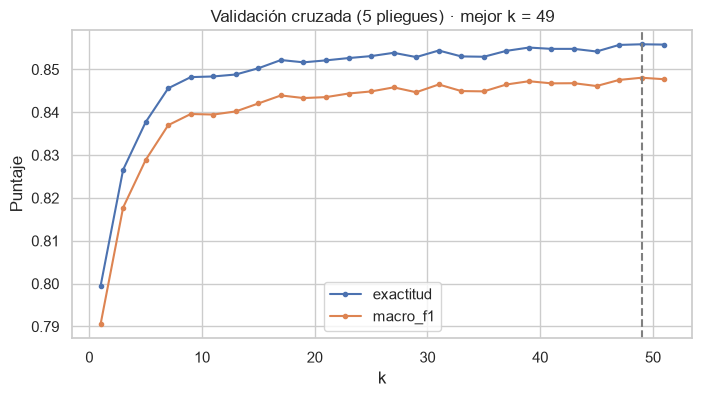

k elegido por macro-F1: 49


,exactitud,macro_f1
k,,
49,0.8559,0.8481


In [7]:
KS = list(range(1, 52, 2))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
filas = []

for pliegue, (a, b) in enumerate(skf.split(X_tr, y_tr)):
    sc = StandardScaler().fit(X_tr[a])
    fi = FisherLDA().fit(sc.transform(X_tr[a]), y_tr[a])
    Za = fi.transform(sc.transform(X_tr[a]))
    Zb = fi.transform(sc.transform(X_tr[b]))

    modelo = KNNClassifier().fit(Za, y_tr[a])
    _, idx = modelo.kneighbors(Zb, k=max(KS))
    for k in KS:
        pred = modelo.predict_from_neighbors(idx[:, :k])
        filas.append({
            "k": k,
            "exactitud": accuracy_score(y_tr[b], pred),
            "macro_f1": f1_score(y_tr[b], pred, average="macro"),
        })

cv = pd.DataFrame(filas).groupby("k").mean()
best_k = int(cv["macro_f1"].idxmax())

fig, ax = plt.subplots(figsize=(8, 4))
cv.plot(ax=ax, marker="o", markersize=3)
ax.axvline(best_k, color="gray", linestyle="--")
ax.set_title(f"Validación cruzada (5 pliegues) · mejor k = {best_k}")
ax.set_ylabel("Puntaje")
plt.show()

print(f"k elegido por macro-F1: {best_k}")
display(cv.loc[[best_k]].round(4))

**Lectura:** si la curva es plana alrededor del mejor k, la elección no es crítica y conviene un valor un poco mayor (más estable). Un k muy bajo suele sobreajustar las zonas donde las clases se traslapan.

## 6. Nivel 1 en el conjunto de prueba (jugadores de campo)

Evaluación del Nivel 1 **aislado**, con las etiquetas reales de campo. Se compara con dos referencias:

- **Mayoría:** predecir siempre la clase más frecuente.
- **KNN sin Fisher:** el mismo KNN sobre todas las métricas de campo estandarizadas (37), para medir cuánto aporta la proyección.

In [8]:
knn = KNNClassifier(k=best_k).fit(Z_tr, y_tr)
Z_te = fisher.transform(scaler.transform(X_te))
pred_te = knn.predict(Z_te)

# Validación: mi KNN debe coincidir con el de scikit-learn
pred_sk = KNeighborsClassifier(n_neighbors=best_k).fit(Z_tr, y_tr).predict(Z_te)
print(f"Acuerdo de mi KNN con scikit-learn: {(pred_te == pred_sk).mean():.4f}")

# Referencias
mayoria = pd.Series(y_tr).value_counts().idxmax()
pred_may = np.full(len(y_te), mayoria)
pred_raw = KNNClassifier(k=best_k).fit(scaler.transform(X_tr), y_tr).predict(scaler.transform(X_te))

tabla = pd.DataFrame({
    "exactitud": [accuracy_score(y_te, p) for p in (pred_may, pred_raw, pred_te)],
    "macro_f1": [f1_score(y_te, p, average="macro") for p in (pred_may, pred_raw, pred_te)],
}, index=[f"Mayoría ({mayoria})", f"KNN sin Fisher ({X_tr.shape[1]}-D, k={best_k})", f"Fisher + KNN (2-D, k={best_k})"]).round(4)
display(tabla)

print(classification_report(y_te, pred_te, labels=ORDEN_CAMPO, digits=3))

Acuerdo de mi KNN con scikit-learn: 1.0000


,exactitud,macro_f1
Mayoría (Medio),0.4094,0.1936
"KNN sin Fisher (37-D, k=49)",0.8623,0.8538
"Fisher + KNN (2-D, k=49)",0.8626,0.8548


              precision    recall  f1-score   support

     Defensa      0.911     0.924     0.917      1235
       Medio      0.818     0.860     0.839      1335
   Delantero      0.866     0.758     0.809       691

    accuracy                          0.863      3261
   macro avg      0.865     0.847     0.855      3261
weighted avg      0.863     0.863     0.862      3261



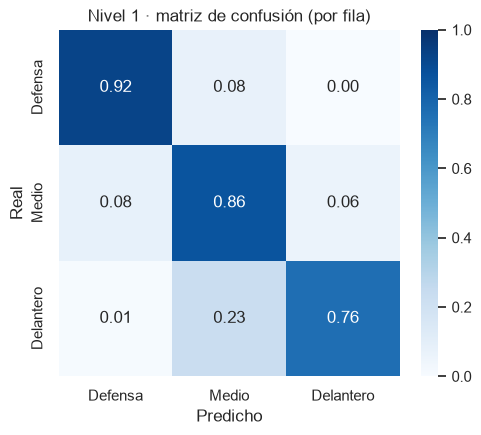

In [9]:
cm = confusion_matrix(y_te, pred_te, labels=ORDEN_CAMPO, normalize="true")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=ORDEN_CAMPO, yticklabels=ORDEN_CAMPO, ax=ax)
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
ax.set_title("Nivel 1 · matriz de confusión (por fila)")
plt.show()

## 7. Pipeline completo en prueba (4 clases)

Aquí se encadenan la compuerta y el Nivel 1 usando **predicciones** en cada etapa, igual que se usaría con un jugador nuevo. Un error de la compuerta o del Nivel 1 se refleja en el resultado final.

Exactitud global: 0.8779
Macro-F1:        0.8911

              precision    recall  f1-score   support

     Portero      1.000     1.000     1.000       409
     Defensa      0.911     0.924     0.917      1235
       Medio      0.818     0.860     0.839      1335
   Delantero      0.866     0.758     0.809       691

    accuracy                          0.878      3670
   macro avg      0.899     0.886     0.891      3670
weighted avg      0.879     0.878     0.877      3670



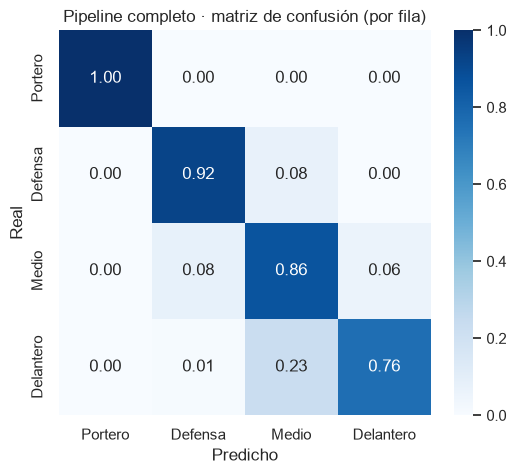

In [10]:
def predecir_pipeline(datos):
    """Etapa 0 + Nivel 1. `datos` es un DataFrame con las columnas de métricas."""
    es_portero = gate.predict(datos[portero_cols]).astype(bool)
    pred = np.empty(len(datos), dtype=object)
    pred[es_portero] = "Portero"
    if (~es_portero).any():
        campo = datos.loc[~es_portero, metricas_campo].to_numpy(dtype=float)
        pred[~es_portero] = knn.predict(fisher.transform(scaler.transform(campo)))
    return pred

pred_final = predecir_pipeline(test)
y_real = test["y_gen"].to_numpy()

print(f"Exactitud global: {accuracy_score(y_real, pred_final):.4f}")
print(f"Macro-F1:        {f1_score(y_real, pred_final, average='macro'):.4f}\n")
print(classification_report(y_real, pred_final, labels=ORDEN_4, digits=3))

cm4 = confusion_matrix(y_real, pred_final, labels=ORDEN_4, normalize="true")
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm4, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=ORDEN_4, yticklabels=ORDEN_4, ax=ax)
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
ax.set_title("Pipeline completo · matriz de confusión (por fila)")
plt.show()

## 8. Análisis de errores por posición específica

¿Qué posiciones concentran los errores? Esto orienta el diseño del Nivel 2 y permite decidir si algunas posiciones (por ejemplo `RM` y `LM`, que mapeamos a Medio) están en la macro-clase equivocada.

In [11]:
res = test[["short_name", "posicion_principal", "y_gen"]].copy()
res["pred"] = pred_final
res["acierto"] = res["pred"] == res["y_gen"]

por_pos = (res.groupby(["posicion_principal", "y_gen"])
              .agg(n=("acierto", "size"), acierto=("acierto", "mean"))
              .reset_index()
              .sort_values("acierto"))
display(por_pos.round(3))

print("\nDestino de las predicciones por posición (proporción por fila):")
display(pd.crosstab(res["posicion_principal"], res["pred"], normalize="index")[ORDEN_4].round(2))

,posicion_principal,y_gen,n,acierto
8,LW,Delantero,83,0.301
12,RW,Delantero,91,0.330
3,CF,Delantero,26,0.423
11,RM,Medio,189,0.746
13,RWB,Defensa,60,0.750
2,CDM,Medio,304,0.770
7,LM,Medio,191,0.785
9,LWB,Defensa,53,0.849
6,LB,Defensa,233,0.888
10,RB,Defensa,237,0.899



Destino de las predicciones por posición (proporción por fila):


pred,Portero,Defensa,Medio,Delantero
posicion_principal,,,,
CAM,0.0,0.00,0.90,0.09
CB,0.0,0.97,0.03,0.00
CDM,0.0,0.23,0.77,0.00
CF,0.0,0.00,0.58,0.42
CM,0.0,0.02,0.98,0.00
GK,1.0,0.00,0.00,0.00
LB,0.0,0.89,0.11,0.00
LM,0.0,0.06,0.79,0.16
LW,0.0,0.04,0.66,0.30


**Lectura:** las posiciones con menor acierto y con predicciones repartidas entre dos clases (por ejemplo, CAM entre Medio y Delantero, o RM/LM entre Medio y Delantero) son las "fronterizas". Si el error es sistemático, la causa suele ser la definición de las clases y no el algoritmo.

## Conclusiones

*Completar tras ejecutar el notebook:*

- Compuerta portero/campo (exactitud, errores):
- Elección de k y estabilidad de la curva:
- Aporte de Fisher frente a KNN sin proyección:
- Recall por clase en el Nivel 1 (¿cuál es la más débil?):
- Posiciones específicas más problemáticas:
- Decisiones para el Nivel 2: